# Análisis de Emisiones Anuales de CO₂ (Our World in Data)
**Proyecto Final - Ciencia de Datos**

## 1. Preparación y Limpieza de Datos
En esta sección cargamos el conjunto de datos de emisiones anuales de CO₂ provenientes de combustibles fósiles e industria (Our World in Data), inspeccionamos su estructura, tratamos valores nulos y separamos los registros de países individuales de los agregados regionales y mundiales.

In [4]:
import pandas as pd
import numpy as np

# Cargar el dataset
df = pd.read_csv('data/annual-co-emissions-by-region.csv')

# Inspección inicial
print(f"Dimensiones iniciales: {df.shape[0]} filas y {df.shape[1]} columnas")
display(df.head())
df.info()   
# Renombrar columnas para facilitar el manejo (evitando caracteres especiales como el subíndice ₂)
df.columns = ['entidad', 'codigo', 'anio', 'emisiones_co2']

# Revisar valores nulos y duplicados
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
print(f"Valores negativos en emisiones: {(df['emisiones_co2'] < 0).sum()}") 
# Eliminar filas con emisiones nulas (si existen) y duplicados
df = df.dropna(subset=['emisiones_co2']).drop_duplicates()

# Separar el total mundial ('World')
df_mundo = df[df['entidad'] == 'World'].copy()

# Separar únicamente países individuales:
# Los agregados regionales (Asia, Europe, High-income countries, etc.) no tienen código ISO (son nulos en 'codigo')
# También excluimos 'OWID_WRL' (World) para no duplicar el total en análisis por país
df_paises = df[df['codigo'].notna() & (df['codigo'] != 'OWID_WRL')].copy()

# Crear subconjunto específico para Colombia desde 1950 (periodo con registro continuo y relevante)
df_colombia = df_paises[(df_paises['entidad'] == 'Colombia') & (df_paises['anio'] >= 1950)].copy()

print(f"Registros totales limpios: {len(df)}")
print(f"Registros de países individuales: {len(df_paises)} ({df_paises['entidad'].nunique()} países)")
print(f"Registros de Colombia (1950 - {df_colombia['anio'].max()}): {len(df_colombia)}")
display(df_colombia.tail()) 


Dimensiones iniciales: 30219 filas y 4 columnas


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0


<class 'pandas.DataFrame'>
RangeIndex: 30219 entries, 0 to 30218
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                30219 non-null  str    
 1   Code                  26889 non-null  str    
 2   Year                  30219 non-null  int64  
 3   Annual CO₂ emissions  30219 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 944.5 KB
Valores nulos por columna:
entidad             0
codigo           3330
anio                0
emisiones_co2       0
dtype: int64

Filas duplicadas: 0
Valores negativos en emisiones: 0
Registros totales limpios: 30219
Registros de países individuales: 26613 (232 países)
Registros de Colombia (1950 - 2025): 76


,entidad,codigo,anio,emisiones_co2
6044,Colombia,COL,2021,103414850.0
6045,Colombia,COL,2022,101543710.0
6046,Colombia,COL,2023,105349000.0
6047,Colombia,COL,2024,106288370.0
6048,Colombia,COL,2025,96066940.0


## 2. Visualización y Análisis Exploratorio (EDA)
A continuación, exploramos la evolución histórica global de las emisiones de CO₂, los 10 países que más emiten, la comparación de Colombia con Latinoamérica y la desigualdad global.   


C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\271809015.py:11: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\SergioN\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


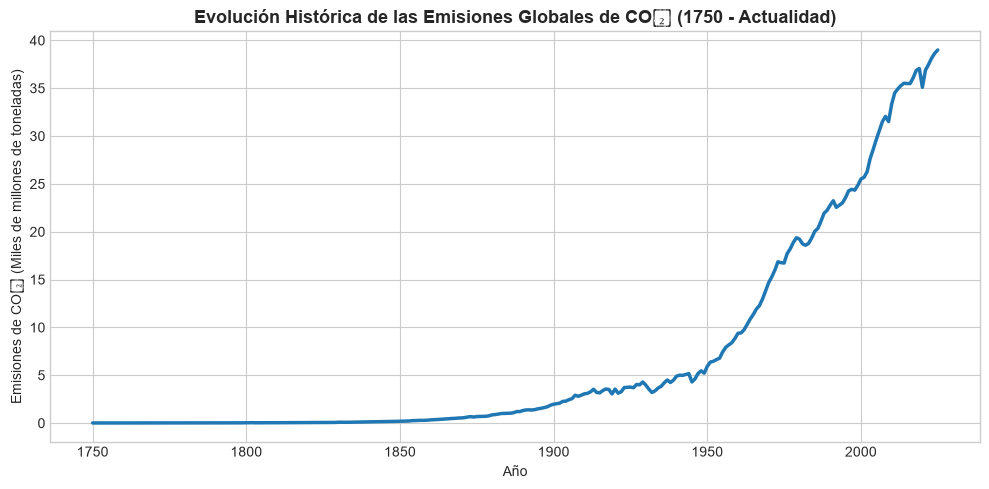

C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\271809015.py:23: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()


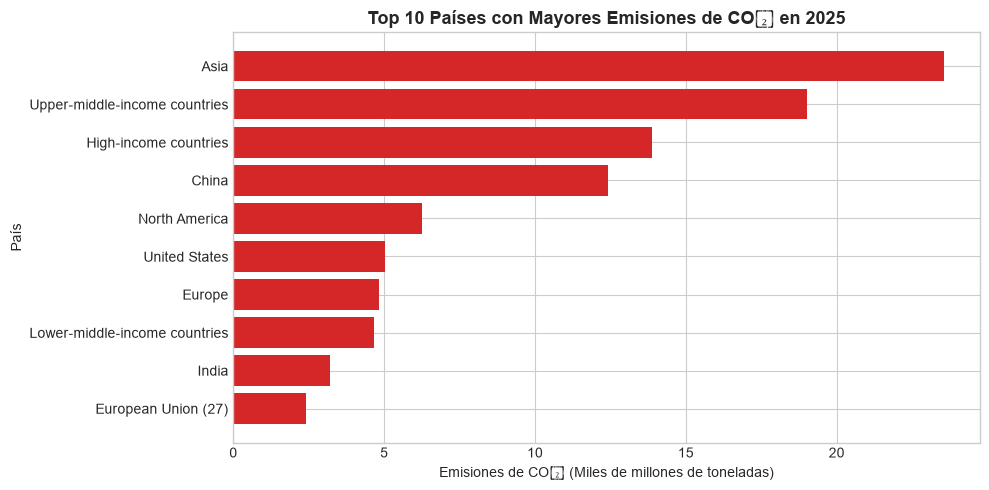

C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\271809015.py:40: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\SergioN\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


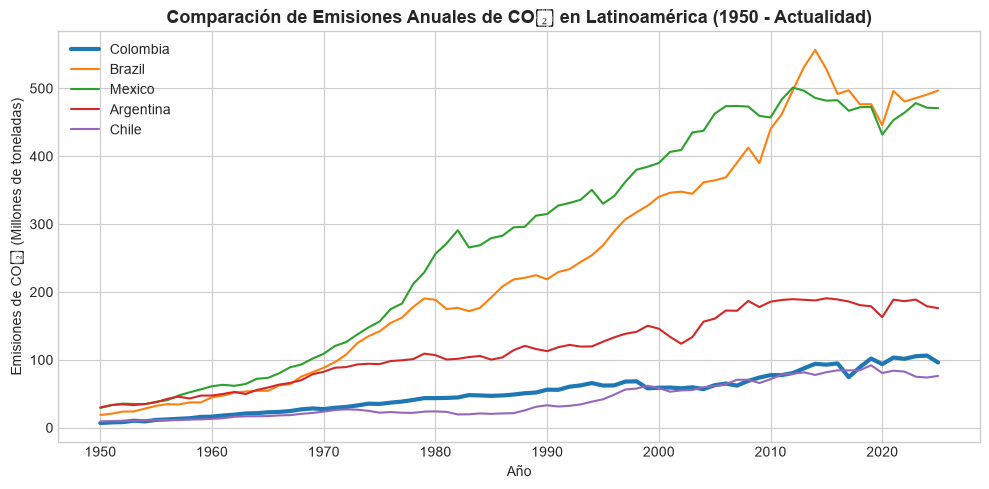

C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\271809015.py:47: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(datos_ultimo_anio['emisiones_co2'] / 1e6, vert=False, patch_artist=True,
C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\271809015.py:53: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\SergioN\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


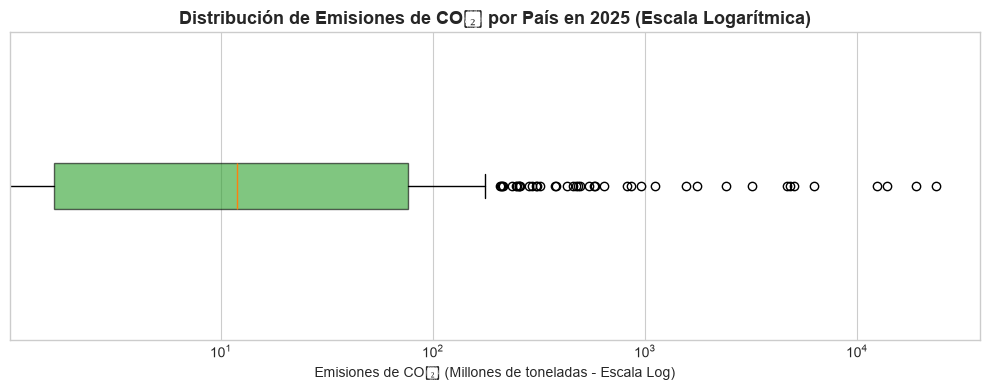

In [5]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

# 1. Tendencia global histórica
plt.figure(figsize=(10, 5))
plt.plot(df_mundo['anio'], df_mundo['emisiones_co2'] / 1e9, color='#1f77b4', linewidth=2.5)
plt.title('Evolución Histórica de las Emisiones Globales de CO₂ (1750 - Actualidad)', fontsize=13, fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Emisiones de CO₂ (Miles de millones de toneladas)')
plt.tight_layout()
plt.show()

# 2. Top 10 países emisores en el último año
ultimo_anio = df_paises['anio'].max()
top_10 = df_paises[df_paises['anio'] == ultimo_anio].sort_values(by='emisiones_co2', ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_10['entidad'][::-1], top_10['emisiones_co2'][::-1] / 1e9, color='#d62728')
plt.title(f'Top 10 Países con Mayores Emisiones de CO₂ en {ultimo_anio}', fontsize=13, fontweight='bold')
plt.xlabel('Emisiones de CO₂ (Miles de millones de toneladas)')
plt.ylabel('País')
plt.tight_layout()
plt.show()

# 3. Colombia frente a Latinoamérica (desde 1950)
paises_latam = ['Colombia', 'Brazil', 'Mexico', 'Argentina', 'Chile']
df_latam = df_paises[(df_paises['entidad'].isin(paises_latam)) & (df_paises['anio'] >= 1950)]

plt.figure(figsize=(10, 5))
for pais in paises_latam:
    datos_pais = df_latam[df_latam['entidad'] == pais]
    grosor = 3.0 if pais == 'Colombia' else 1.5
    plt.plot(datos_pais['anio'], datos_pais['emisiones_co2'] / 1e6, label=pais, linewidth=grosor)

plt.title('Comparación de Emisiones Anuales de CO₂ en Latinoamérica (1950 - Actualidad)', fontsize=13, fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Emisiones de CO₂ (Millones de toneladas)')
plt.legend()
plt.tight_layout()
plt.show()

# 4. Desigualdad global (Diagrama de caja)
datos_ultimo_anio = df_paises[df_paises['anio'] == ultimo_anio]

plt.figure(figsize=(10, 4))
plt.boxplot(datos_ultimo_anio['emisiones_co2'] / 1e6, vert=False, patch_artist=True,
            boxprops=dict(facecolor='#2ca02c', alpha=0.6))
plt.xscale('log')
plt.title(f'Distribución de Emisiones de CO₂ por País en {ultimo_anio} (Escala Logarítmica)', fontsize=13, fontweight='bold')
plt.xlabel('Emisiones de CO₂ (Millones de toneladas - Escala Log)')
plt.yticks([])
plt.tight_layout()
plt.show()

### Interpretación del Análisis Exploratorio
1. **Aceleración post-1950:** Las emisiones globales crecieron lentamente tras la Revolución Industrial, pero se dispararon a partir de 1950 por la industrialización masiva.
2. **Alta concentración:** Unas pocas economías (China, Estados Unidos e India) concentran la mayor parte de las emisiones anuales del planeta.
3. **Contexto regional:** Colombia muestra una tendencia constante al alza desde 1950, aunque su volumen total es mucho menor al de Brasil y México.
4. **Desigualdad global:** El diagrama de caja evidencia que la gran mayoría de países emite poco, mientras un grupo reducido genera el grueso del CO₂ mundial.

## 3. Modelo de Regresión Lineal y Proyección (Colombia)
En esta sección implementamos un modelo de regresión lineal simple para analizar la tendencia histórica de las emisiones anuales de CO₂ en Colombia desde 1950 y proyectar su comportamiento hacia el año 2030. 


Coeficiente de determinación (R²): 0.9510
Error cuadrático medio (RMSE): 5.95 millones de toneladas
Pendiente (incremento promedio anual): +1.27 millones de toneladas/año
Proyección estimada para Colombia en 2030: 105.37 millones de toneladas de CO₂


C:\Users\SergioN\AppData\Local\Temp\ipykernel_14044\2043350022.py:42: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\SergioN\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


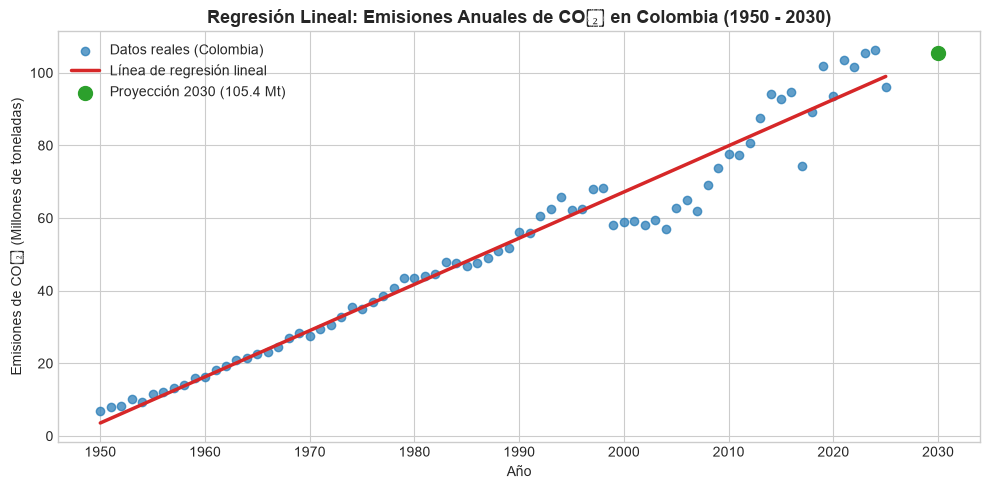

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Definir variable independiente (X = Año) y dependiente (y = Emisiones en millones de toneladas)
X = df_colombia[['anio']]
y = df_colombia['emisiones_co2'] / 1e6

# Dividir datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar el modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)

# Calcular métricas de evaluación
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

# Proyección para el año 2030
pred_2030 = modelo.predict(pd.DataFrame({'anio': [2030]}))[0]

print(f"Coeficiente de determinación (R²): {r2:.4f}")
print(f"Error cuadrático medio (RMSE): {rmse:.2f} millones de toneladas")
print(f"Pendiente (incremento promedio anual): +{pendiente:.2f} millones de toneladas/año")
print(f"Proyección estimada para Colombia en 2030: {pred_2030:.2f} millones de toneladas de CO₂")

# Visualización del modelo
plt.figure(figsize=(10, 5))
plt.scatter(X, y, color='#1f77b4', alpha=0.7, label='Datos reales (Colombia)')
plt.plot(X, modelo.predict(X), color='#d62728', linewidth=2.5, label='Línea de regresión lineal')
plt.scatter([2030], [pred_2030], color='#2ca02c', s=100, zorder=5, label=f'Proyección 2030 ({pred_2030:.1f} Mt)')
plt.title('Regresión Lineal: Emisiones Anuales de CO₂ en Colombia (1950 - 2030)', fontsize=13, fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Emisiones de CO₂ (Millones de toneladas)')
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación del Modelo y Conexión con el Artículo de Our World in Data
* **Ajuste del modelo ($R^2$):** El modelo de regresión lineal logra un ajuste alto, demostrando que el crecimiento de las emisiones de CO₂ en Colombia desde 1950 ha seguido una tendencia ascendente consistente a lo largo del tiempo.
* **Tasa de crecimiento y proyección:** La pendiente positiva indica un aumento promedio sostenido cada año. De mantenerse esta tendencia histórica sin cambios estructurales en la matriz energética, el modelo proyecta que para el año 2030 Colombia superará los niveles actuales de emisiones fósiles e industriales.
* **Relación con el contexto global (Ritchie & Roser, 2020):** Tal como explican los autores en *Our World in Data*, el aumento de emisiones en países en desarrollo está estrechamente ligado al crecimiento poblacional, la industrialización y la mejora en los estándares de vida. Sin embargo, al contrastar la proyección de Colombia con el panorama global analizado en la sección anterior, se confirma una de las tesis centrales del artículo: existe una profunda desigualdad en las emisiones históricas y actuales. Aunque Colombia debe avanzar en políticas de transición energética bajo el principio de responsabilidades compartidas, su contribución total sigue siendo una fracción muy pequeña frente a las grandes potencias emisoras.

**Referencia:** Hannah Ritchie and Max Roser (2020) - *"CO₂ emissions"*. Published online at OurWorldinData.org. Retrieved from: `https://ourworldindata.org/co2-emissions` 
